# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [8]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path

# Colab upload is optional; this notebook also works in local Jupyter.
try:
    from google.colab import files
except ImportError:
    files = None

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [9]:
# Use the dataset supplied with the lab (no fabricated data).
filename = "Lab_11_QnA_Dataset.csv"
candidates = [Path("/content") / filename, Path.cwd() / filename]
csv_path = next((p for p in candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        f"Place {filename} in the notebook folder (Jupyter) or /content (Colab), then rerun this cell."
    )
df = pd.read_csv(csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Map any answer IDs to consecutive class indices for cross_entropy.
answer_codes, answer_labels = pd.factorize(df["answer_id"], sort=True)
y = torch.tensor(answer_codes, dtype=torch.long)

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [11]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))
        scores = self.att(h).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)  # do not attend to padding
        weights = torch.softmax(scores, dim=1)
        context = (h * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

model.train()
for epoch in range(50):
    optimizer.zero_grad()  # reset gradients before each update
    loss = nn.functional.cross_entropy(model(X)[0], y)
    loss.backward()
    optimizer.step()

print("Training finished! Final loss:", round(loss.item(), 4))

Training finished! Final loss: 0.0688


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

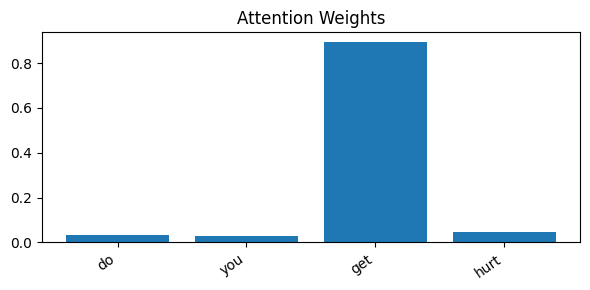

In [13]:
question = df["question"].iloc[0]
word_ids = tokenizer.texts_to_sequences([question])[0]
words = [tokenizer.index_word[i] for i in word_ids]

model.eval()
with torch.no_grad():
    prediction, weights = model(X[:1])

plt.figure(figsize=(max(6, len(words) * 0.9), 3))
plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

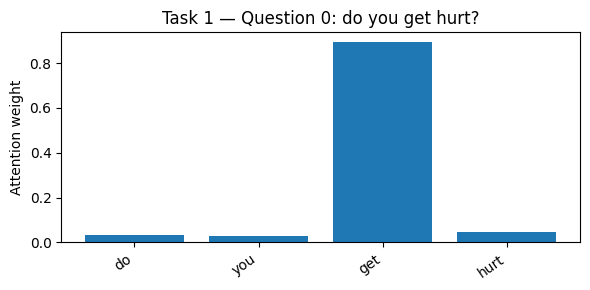

Highest attention: 'get' (0.893)


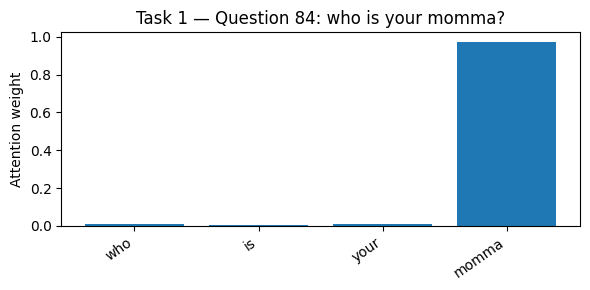

Highest attention: 'momma' (0.976)


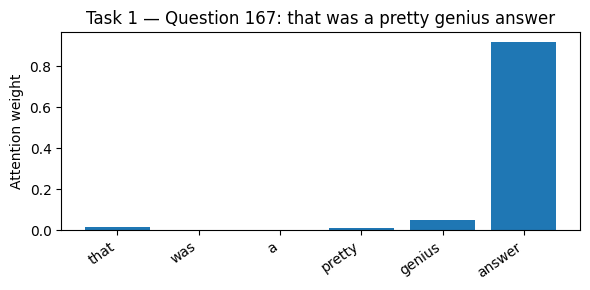

Highest attention: 'answer' (0.920)

Task 1 — Interpretation
The highest-attention words are shown above for all three questions.
They may be important content words, but high attention alone does not prove
that a word is semantically important. Check each word in its question context.


In [14]:
# Task 1 — Visualize attention for three different questions.
# Select three spread-out examples to avoid assuming any specific dataset rows.
if len(df) < 3:
    raise ValueError("Task 1 requires at least three questions.")
indices = [0, len(df) // 2, len(df) - 1]
model.eval()
task1_results = []

for idx in indices:
    question = df["question"].iloc[idx]
    ids = tokenizer.texts_to_sequences([question])[0]
    words = [tokenizer.index_word[t] for t in ids]
    with torch.no_grad():
        _, attention = model(X[idx:idx+1])
    values = attention[0, :len(words)].cpu().numpy()
    top_index = int(values.argmax())
    task1_results.append((question, words[top_index], float(values[top_index])))

    plt.figure(figsize=(max(6, len(words) * 0.85), 3))
    plt.bar(range(len(words)), values)
    plt.xticks(range(len(words)), words, rotation=35, ha="right")
    plt.ylabel("Attention weight")
    plt.title(f"Task 1 — Question {idx}: {question}")
    plt.tight_layout()
    plt.show()
    print(f"Highest attention: '{words[top_index]}' ({values[top_index]:.3f})")

print("\nTask 1 — Interpretation")
print("The highest-attention words are shown above for all three questions.")
print("They may be important content words, but high attention alone does not prove")
print("that a word is semantically important. Check each word in its question context.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Candidate questions with the same answer_id (check their meanings):
Q1: what do you like to be called?
Q2: so what do you like to be called?
Similarity score: 0.952


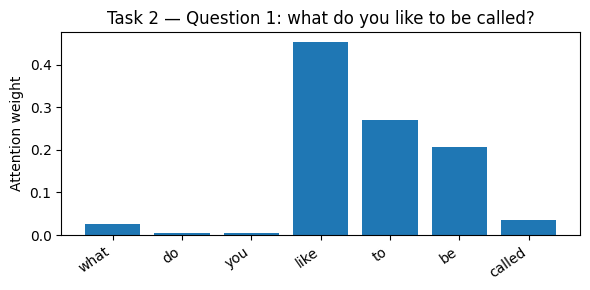

Question 1 highest attention word: 'like'


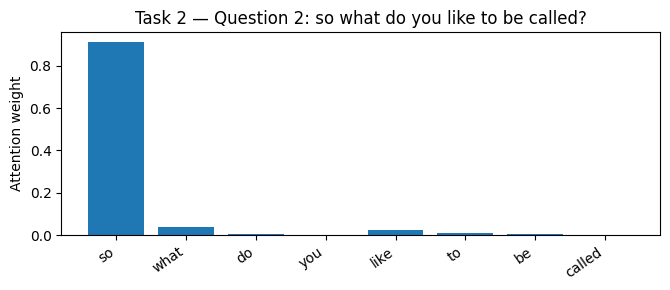

Question 2 highest attention word: 'so'

Task 2 — Interpretation
The questions gave the highest attention to different words: like and so
This suggests attention can shift across different wordings.
Attention weights depend on the trained model and input; they do not
by themselves prove that the model understood the questions' meaning.


In [15]:
# Task 2 — Find two differently worded questions with the same answer_id.
# This is a reproducible proxy for similar meaning; verify the chosen pair below.
from difflib import SequenceMatcher

best_pair, best_score = None, -1.0
for _, group in df.groupby("answer_id", sort=False):
    indices_in_group = group.index.tolist()
    # Limit comparisons to keep this cell practical for larger datasets.
    indices_in_group = indices_in_group[:60]
    for pos, i in enumerate(indices_in_group):
        for j in indices_in_group[pos+1:]:
            q1, q2 = str(df.loc[i, "question"]), str(df.loc[j, "question"])
            if q1 == q2:
                continue
            score = SequenceMatcher(None, q1, q2).ratio()
            if score > best_score:
                best_score, best_pair = score, (i, j)

if best_pair is None:
    raise ValueError("No two differently worded questions share an answer_id. Select a pair manually.")

print("Candidate questions with the same answer_id (check their meanings):")
print("Q1:", df.loc[best_pair[0], "question"])
print("Q2:", df.loc[best_pair[1], "question"])
print("Similarity score:", round(best_score, 3))

model.eval()
task2_results = []
for label, idx in zip(("Question 1", "Question 2"), best_pair):
    question = df.loc[idx, "question"]
    ids = tokenizer.texts_to_sequences([question])[0]
    words = [tokenizer.index_word[t] for t in ids]
    with torch.no_grad():
        logits, attention = model(X[idx:idx+1])
    values = attention[0, :len(words)].cpu().numpy()
    top_word = words[int(values.argmax())]
    task2_results.append((question, top_word, int(logits.argmax(dim=1).item())))

    plt.figure(figsize=(max(6, len(words) * 0.85), 3))
    plt.bar(range(len(words)), values)
    plt.xticks(range(len(words)), words, rotation=35, ha="right")
    plt.ylabel("Attention weight")
    plt.title(f"Task 2 — {label}: {question}")
    plt.tight_layout()
    plt.show()
    print(f"{label} highest attention word: '{top_word}'")

print("\nTask 2 — Interpretation")
if task2_results[0][1] == task2_results[1][1]:
    print("Both questions gave the highest attention to the same word:", task2_results[0][1])
    print("This suggests the model may rely on a shared word for these two inputs.")
else:
    print("The questions gave the highest attention to different words:",
          task2_results[0][1], "and", task2_results[1][1])
    print("This suggests attention can shift across different wordings.")
print("Attention weights depend on the trained model and input; they do not")
print("by themselves prove that the model understood the questions' meaning.")